# Q12 - Expanding the Action Space by Combining Two Basic Actions

Same code as `q12_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q12 - Expanding the action space by combining two basic actions (grid treasure game).

Basic actions: Up, Down, Left, Right, Jump. A combined action = two basic actions done together
(Up+Right = diagonal step, Jump+Right = leap two cells over a wall). We run iterative
deepening (depth = number of moves) with the basic and with the expanded action set, and show
that a bigger action space gives a bigger search space and a better goal value G(A, S_d).
"""
import itertools
import os

import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

BASIC = {"Up": (-1, 0), "Down": (1, 0), "Left": (0, -1), "Right": (0, 1), "Jump": None}
MAP = [
    "S..#...3.",
    ".#.#.###.",
    ".#...#5..",
    ".###.#.#.",
    "4..#...#.",
    ".#.###.#.",
    ".#..2#...",
    ".#####.#.",
    "6......#E",
]
EXIT_BONUS = 10


def build_actions() -> tuple:
    """Basic moves, then every meaningful pair of basic actions as one new action."""
    basic = {k: (v, 1) for k, v in BASIC.items() if v}          # (direction, cells moved)
    combined, cancelled = {}, []
    for a, b in itertools.combinations(BASIC, 2):
        if "Jump" in (a, b):                                    # Jump + direction = leap 2
            d = BASIC[b if a == "Jump" else a]
            combined[f"Jump+{b if a == 'Jump' else a}"] = (d, 2)
            continue
        dr, dc = BASIC[a][0] + BASIC[b][0], BASIC[a][1] + BASIC[b][1]
        if (dr, dc) == (0, 0):
            cancelled.append(f"{a}+{b}")                        # Up+Down does nothing
        else:
            combined[f"{a}+{b}"] = ((dr, dc), 1)                # diagonal step
    return basic, {**basic, **combined}, cancelled


def step(pos: tuple, move: tuple, grid: list):
    (dr, dc), cells = move
    r, c = pos[0] + dr * cells, pos[1] + dc * cells
    if 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] != "#":
        return (r, c)
    return None


GRID = [list(row) for row in MAP]
START = next((r, c) for r, row in enumerate(MAP) for c, ch in enumerate(row) if ch == "S")
COINS = {(r, c): int(ch) for r, row in enumerate(MAP) for c, ch in enumerate(row) if ch.isdigit()}
COIN_IDS = {pos: i for i, pos in enumerate(COINS)}


def value(pos: tuple, mask: int) -> int:
    coins = sum(v for p, v in COINS.items() if mask >> COIN_IDS[p] & 1)
    return coins + (EXIT_BONUS if MAP[pos[0]][pos[1]] == "E" else 0)


def depth_limited(actions: dict, limit: int):
    """DLS over (position, coins collected). Returns states seen and the best path found."""
    best_left = {}
    best = {"value": -1, "path": None}

    def dfs(pos: tuple, mask: int, left: int, path: list) -> None:
        if best_left.get((pos, mask), -1) >= left:
            return                                              # already explored deeper
        best_left[(pos, mask)] = left
        if value(pos, mask) > best["value"]:
            best.update(value=value(pos, mask), path=list(path))
        if left == 0:
            return
        for move in actions.values():
            nxt = step(pos, move, GRID)
            if nxt:
                new_mask = mask | (1 << COIN_IDS[nxt]) if nxt in COINS else mask
                dfs(nxt, new_mask, left - 1, path + [nxt])

    dfs(START, 0, limit, [START])
    return len(best_left), best["value"], best["path"]


def open_grid_count(actions: dict, d: int) -> int:
    grid = [["."] * 21 for _ in range(21)]
    frontier, seen = {(10, 10)}, {(10, 10)}
    for _ in range(d):
        frontier = {n for p in frontier for m in actions.values()
                    if (n := step(p, m, grid)) and n not in seen}
        seen |= frontier
    return len(seen)


basic, full, cancelled = build_actions()
diag_only = {k: v for k, v in full.items() if v[1] == 1}
print("Q12  Expanding the action space in a grid treasure game")
print(f"basic actions: {', '.join(BASIC)}  ->  {len(basic)} moves")
print(f"pairs of basic actions: {len(list(itertools.combinations(BASIC, 2)))}, "
      f"cancelled: {', '.join(cancelled)}")
print(f"new combined actions: {', '.join(k for k in full if k not in basic)}")
print(f"action space: {len(basic)} -> {len(full)} moves")
print("Open grid - cells reachable within d moves (theory in brackets)")
print("  d | 4 basic (2d^2+2d+1) | +diagonals (2d+1)^2 | +diagonals+jumps")
open_counts = []
for d in range(1, 6):
    row = (open_grid_count(basic, d), open_grid_count(diag_only, d), open_grid_count(full, d))
    open_counts.append(row)
    print(f"  {d} | {row[0]:>4} ({2 * d * d + 2 * d + 1:>3})        | {row[1]:>4} ({(2 * d + 1) ** 2:>3})"
          f"         | {row[2]:>4}")

print("Game map: iterative deepening, goal G(A, S_d) = best value reachable in d moves")
print("  d | states, basic | G(basic) | states, combined | G(combined)")
game = []
for d in range(1, 11):
    nb, gb, pb = depth_limited(basic, d)
    nc, gc, pc = depth_limited(full, d)
    game.append((d, nb, gb, pb, nc, gc, pc))
    print(f" {d:>2} | {nb:>13} | {gb:>8} | {nc:>16} | {gc:>11}")
SHOW = 8
_, _, gb8, pb8, _, gc8, pc8 = game[SHOW - 1]
print(f"d={SHOW}: basic value {gb8}, path ends {pb8[-1]}; combined value {gc8}, path ends {pc8[-1]}")

# ---------------- chart 1: reachable states per depth ----------------
ds = range(1, 6)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
a1.plot(ds, [c[0] for c in open_counts], "o-", color="#3a6ea5", label="4 basic moves")
a1.plot(ds, [c[1] for c in open_counts], "s-", color="#e76f51", label="+ diagonal (Up+Right ...)")
a1.plot(ds, [c[2] for c in open_counts], "^-", color="#2a9d8f", label="+ diagonal + jump")
a1.plot(ds, [2 * d * d + 2 * d + 1 for d in ds], "x", ms=11, mew=2, color="#1e3a8a",
        label="theory 2d^2+2d+1")
a1.plot(ds, [(2 * d + 1) ** 2 for d in ds], "x", ms=11, mew=2, color="#9a3412",
        label="theory (2d+1)^2")
a1.set_xticks(list(ds))
a1.set_xlabel("depth d (moves)")
a1.set_ylabel("cells reachable")
a1.set_title("Open grid: bigger action space -> bigger search space")
a1.legend(fontsize=8)
a2.plot([g[0] for g in game], [g[2] for g in game], "o-", color="#3a6ea5", label="G(A_basic, d)")
a2.plot([g[0] for g in game], [g[5] for g in game], "s-", color="#e76f51",
        label="G(A_combined, d)")
a2.set_xlabel("depth d (moves allowed)")
a2.set_ylabel("best value reachable (coins + exit)")
a2.set_title("Goal value as a function of A and S_d")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q12_chart1_search_space.png")
plt.close(fig)

# ---------------- chart 2: game map with both best paths ----------------
fig, ax = plt.subplots(figsize=(5.6, 5.6))
for r, row in enumerate(MAP):
    for c, ch in enumerate(row):
        color = "#374151" if ch == "#" else "#f9fafb"
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color=color, ec="#d1d5db"))
        if ch.isdigit():
            ax.scatter(c, r, s=420, color="#f4c430", zorder=3)
            ax.text(c, r, ch, ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
ax.text(START[1], START[0], "S", ha="center", va="center", fontsize=12, color="#2a9d8f",
        fontweight="bold")
ax.text(8, 8, "E", ha="center", va="center", fontsize=12, color="#d62828", fontweight="bold")
for path, col, lab, off in [(pb8, "#3a6ea5", f"basic moves (value {gb8})", -0.12),
                            (pc8, "#e76f51", f"combined moves (value {gc8})", 0.12)]:
    ax.plot([p[1] + off for p in path], [p[0] + off for p in path], "-o", color=col, lw=2.2,
            ms=4, label=lab, zorder=5)
ax.set_xlim(-0.5, 8.5)
ax.set_ylim(8.5, -0.5)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"Best paths with {SHOW} moves", fontsize=10.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=1, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("images/q12_chart2_game_paths.png")
plt.close(fig)
print("charts saved to images/")


Q12  Expanding the action space in a grid treasure game
basic actions: Up, Down, Left, Right, Jump  ->  4 moves
pairs of basic actions: 10, cancelled: Up+Down, Left+Right
new combined actions: Up+Left, Up+Right, Jump+Up, Down+Left, Down+Right, Jump+Down, Jump+Left, Jump+Right
action space: 4 -> 12 moves
Open grid - cells reachable within d moves (theory in brackets)
  d | 4 basic (2d^2+2d+1) | +diagonals (2d+1)^2 | +diagonals+jumps
  1 |    5 (  5)        |    9 (  9)         |   13
  2 |   13 ( 13)        |   25 ( 25)         |   41
  3 |   25 ( 25)        |   49 ( 49)         |   85
  4 |   41 ( 41)        |   81 ( 81)         |  145
  5 |   61 ( 61)        |  121 (121)         |  221
Game map: iterative deepening, goal G(A, S_d) = best value reachable in d moves
  d | states, basic | G(basic) | states, combined | G(combined)
  1 |             3 |        0 |                5 |           0
  2 |             5 |        0 |               10 |           4
  3 |             7 |        0 |

charts saved to images/


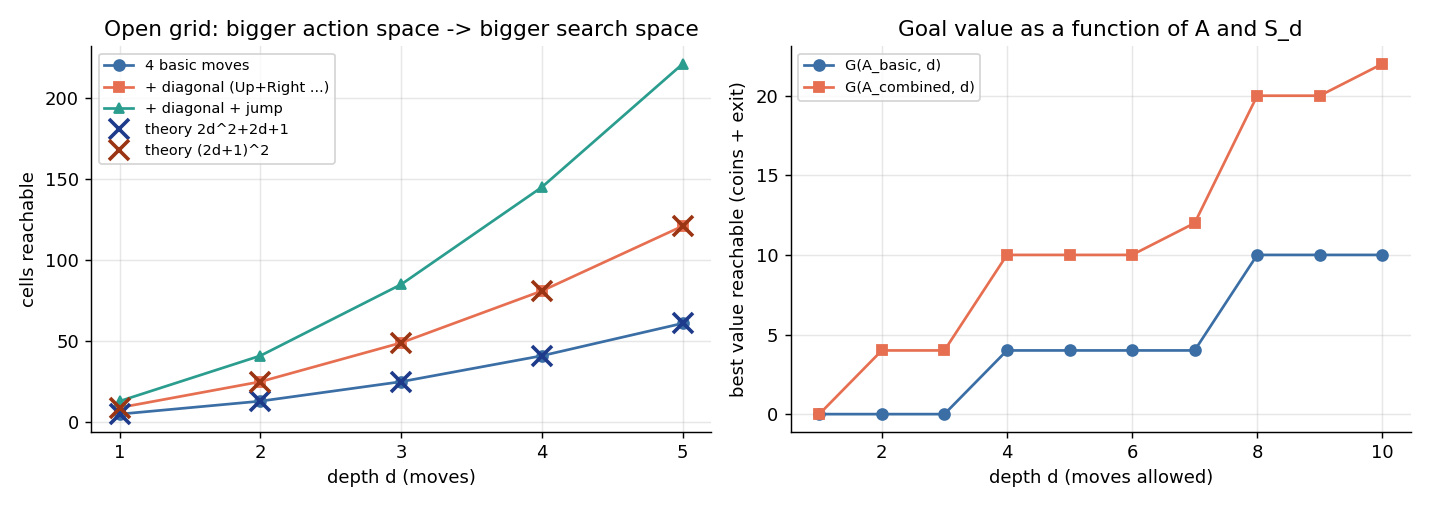

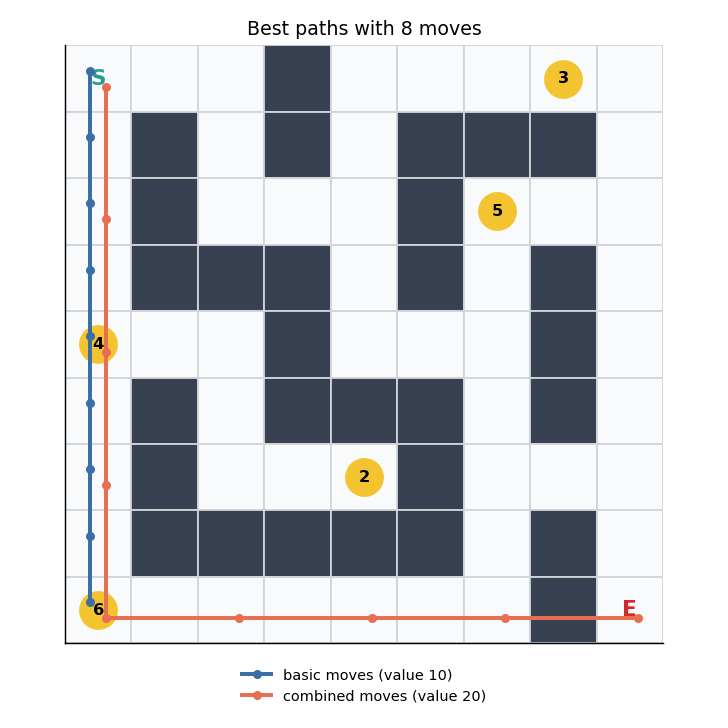

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q12_chart*.png')):
    display(Image(p))